# Exploratory Data Analysis and Deep Learning-Based Prediction of Heart Disease Risk

**Academic Project Notebook**  
**Course Assignment:** Exploratory Data Analysis and Visualization of a Real-World Dataset  
**Domain:** Applied Biomedical Machine Learning, Health Informatics, and Statistical Epidemiology  

---

### Executive Summary & Workflow Architecture
This Jupyter Notebook implements a fully self-contained, reproducible, end-to-end data science and deep learning workflow:
1. **Dataset Profiling:** Rigorous inspection of schema, cardinality, missing values, duplicates, and target class balance.
2. **Leak-Free Preprocessing:** Three-way stratified partitioning (70% Train, 15% Validation, 15% Test) with pipeline fitted exclusively on training data.
3. **Exploratory Data Analysis (EDA):** Parametric and non-parametric statistical metrics, cross-tabulations, and Chi-square independence tests.
4. **Data Visualizations:** 8 high-resolution publication-grade figures covering distributions, outlier detection, correlation heatmaps, and prevalence trends.
5. **Feature Importance Analysis:** Information-theoretic Mutual Information and model-agnostic Permutation Importance.
6. **Deep Learning Model Development:** Multi-Layer Perceptron (MLP) constructed in TensorFlow/Keras with Dropout and Batch Normalization.
7. **Validation-Driven Hyperparameter Tuning:** Grid search across 10 distinct neural network configurations evaluated strictly on validation data.
8. **Final Model Evaluation:** Independent benchmark on the untouched test set (N=150) featuring ROC-AUC, Sensitivity, Specificity, Confusion Matrix, and 4 diagnostic plots.
9. **Inference Function & Scenario Testing:** Real-time risk probability calculation and clinical indicator extraction.


In [1]:
# 1. Imports and Environmental Configuration
import os
import sys
from pathlib import Path

# Set up project root directory and change working directory to root
PROJECT_ROOT = Path(os.getcwd()).parent if os.path.basename(os.getcwd()) == 'notebooks' else Path(os.getcwd())
os.chdir(str(PROJECT_ROOT))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Global plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Arial'

print(f"TensorFlow Version: {tf.__version__}")
print(f"Pandas Version: {pd.__version__}")
print("Active Working Directory:", os.getcwd())


TensorFlow Version: 2.21.0
Pandas Version: 3.0.6
Active Working Directory: d:\heart-disease-risk-prediction


## 2. Dataset Inspection & Profiling
We load the raw survey dataset (`data/raw/heart.csv`) and examine feature schema, missing values, duplicates, and target distribution.


In [2]:
from src.data_loader import load_data, inspect_dataset

data_path = os.path.join(PROJECT_ROOT, 'data', 'raw', 'heart.csv')
raw_df = load_data(data_path)
print(f"Dataset Shape: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
display(raw_df.head())

profile = inspect_dataset(raw_df)
print("\n--- Dataset Summary Audit ---")
print(f"Missing Values: {sum(profile['missing_counts'].values())} (100% complete)")
print(f"Duplicate Rows: {profile['duplicate_rows']}")
print(f"Target Column: {profile['target_profile']['target_column']}")
print(f"Target Class Counts: {profile['target_profile']['counts']}")
print(f"Imbalance Ratio: {profile['target_profile']['imbalance_ratio']}:1 (Majority to Minority)")


2026-10-14 14:55:11,038 - INFO - Loading dataset from: d:\heart-disease-risk-prediction\data\raw\heart.csv (extension: .csv)


2026-10-14 14:55:11,050 - INFO - Loaded 999 rows and 11 columns successfully.


Dataset Shape: 999 rows, 11 columns


,General_Health,Exercise,Depression,Diabetes,Sex,Age_Category,Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Heart_Disease
0,Poor,No,No,No,Female,70-74,32.66,14.54,Yes,No,No
1,Very Good,No,No,Yes,Female,70-74,77.11,28.29,No,No,Yes
2,Very Good,Yes,No,Yes,Female,60-64,88.45,33.47,No,No,No
3,Poor,Yes,No,Yes,Male,75-79,93.44,28.73,No,Yes,Yes
4,Good,No,No,No,Male,80+,88.45,24.37,Yes,Yes,No



--- Dataset Summary Audit ---
Missing Values: 0 (100% complete)
Duplicate Rows: 0
Target Column: Heart_Disease
Target Class Counts: {'No': 858, 'Yes': 141}
Imbalance Ratio: 6.09:1 (Majority to Minority)


## 3. Data Preprocessing & Leak-Free Partitioning
To guarantee zero data leakage:
- Data is partitioned into **Training (70%)**, **Validation (15%)**, and **Test (15%)** splits using stratified sampling.
- The `HeartDiseasePreprocessor` (incorporating `StandardScaler` and `OneHotEncoder`) is fitted **strictly on the training split**.
- The untouched test split is set aside until final benchmark evaluation.


In [3]:
from src.data_preprocessing import run_preprocessing_pipeline

meta = run_preprocessing_pipeline(
    raw_path=data_path,
    output_dir=os.path.join(PROJECT_ROOT, 'data', 'processed'),
    models_dir=os.path.join(PROJECT_ROOT, 'models')
)

print(f"Engineered Feature Dimensions: {meta['num_features']}")
print("Training Split Distribution:", meta['train_class_distribution'])
print("Validation Split Distribution:", meta['val_class_distribution'])
print("Test Split Distribution (Untouched):", meta['test_class_distribution'])


2026-10-14 14:55:15,999 - INFO - Starting preprocessing pipeline for dataset with 999 records.
2026-10-14 14:55:16,039 - INFO - Split sizes: Train=699 (70.0%), Val=150 (15.0%), Test=150 (15.0%)
2026-10-14 14:55:16,054 - INFO - Preprocessor fitted successfully. Total engineered features: 32
2026-10-14 14:55:16,074 - INFO - Preprocessor saved to d:\heart-disease-risk-prediction\models\preprocessor.joblib
2026-10-14 14:55:16,090 - INFO - Processed splits saved to d:\heart-disease-risk-prediction\data\processed
2026-10-14 14:55:16,091 - INFO - Preprocessing completed. Feature count: 32


Engineered Feature Dimensions: 32
Training Split Distribution: {'0 (No)': 600, '1 (Yes)': 99, 'prevalence_pct': 14.16}
Validation Split Distribution: {'0 (No)': 129, '1 (Yes)': 21, 'prevalence_pct': 14.0}
Test Split Distribution (Untouched): {'0 (No)': 129, '1 (Yes)': 21, 'prevalence_pct': 14.0}


## 4. Exploratory Data Analysis & Descriptive Statistics
We calculate parametric and non-parametric central tendencies, dispersion, and statistical shape metrics (skewness, kurtosis, IQR) for continuous and categorical predictors.


In [4]:
from src.exploratory_analysis import compute_numerical_statistics, compute_bivariate_categorical, compute_correlations

num_stats = compute_numerical_statistics(raw_df, ['Weight_(kg)', 'BMI'])
print("--- Continuous Attributes Descriptive Statistics ---")
display(num_stats)

biv_cat = compute_bivariate_categorical(raw_df, [
    'General_Health', 'Exercise', 'Depression', 'Diabetes',
    'Sex', 'Age_Category', 'Smoking_History', 'Alcohol_Consumption'
], target_col='Heart_Disease')

print("\n--- Categorical Chi-Square Significance Summary ---")
cat_summary_rows = []
for col, res in biv_cat.items():
    cat_summary_rows.append({
        'Feature': col,
        'Chi2_Stat': res['chi2_statistic'],
        'p_value': res['p_value'],
        'Significant (alpha=0.05)': res['statistically_significant']
    })
display(pd.DataFrame(cat_summary_rows).sort_values(by='Chi2_Stat', ascending=False))


--- Continuous Attributes Descriptive Statistics ---


,Feature,Count,Mean,Median,Mode,Std_Dev,Variance,Min,Q1_25%,Q3_75%,IQR,Max,Skewness,Kurtosis
0,Weight_(kg),999,80.999409,79.38,81.65,19.803497,392.178476,32.66,67.59,91.17,23.58,167.83,0.664831,0.754260
1,BMI,999,28.560350,27.78,27.46,6.221840,38.711298,14.06,24.21,31.89,7.68,51.81,0.783168,0.937277



--- Categorical Chi-Square Significance Summary ---


,Feature,Chi2_Stat,p_value,Significant (alpha=0.05)
0,General_Health,83.3103,3.462405e-17,True
5,Age_Category,31.9594,1.403873e-03,True
4,Sex,21.1681,4.207131e-06,True
3,Diabetes,18.5900,1.620702e-05,True
6,Smoking_History,16.7963,4.161382e-05,True
1,Exercise,1.6374,2.006876e-01,False
7,Alcohol_Consumption,1.4862,2.228120e-01,False
2,Depression,0.3255,5.683097e-01,False


## 5. High-Resolution Data Visualizations
We generate and examine the 8 required figures illustrating target balance, distribution curves, outlier boundaries, correlation structures, and clinical risk trends.


2026-10-14 14:55:22,252 - INFO - Generating EDA visualizations for 999 records...


d:\heart-disease-risk-prediction\src\visualizations.py:158: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="Heart_Disease", y="BMI", data=df, ax=axes[0], palette=["#2b5c8f", "#d95f02"], inner="quartile", cut=0)
d:\heart-disease-risk-prediction\src\visualizations.py:163: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Heart_Disease", y="Weight_(kg)", data=df, ax=axes[1], palette=["#2b5c8f", "#d95f02"], width=0.45)
2026-10-14 14:55:26,493 - INFO - Visualization interpretations report generated at: outputs/reports/visualization_interpretations.md
2026-10-14 14:55:26,495 - INFO - All 8 visualizations generated successfully in d:\heart-disease-risk-prediction\outputs\figures


All figures generated successfully. Displaying selected key figures:

--- Figure 1: Target Class Distribution ---


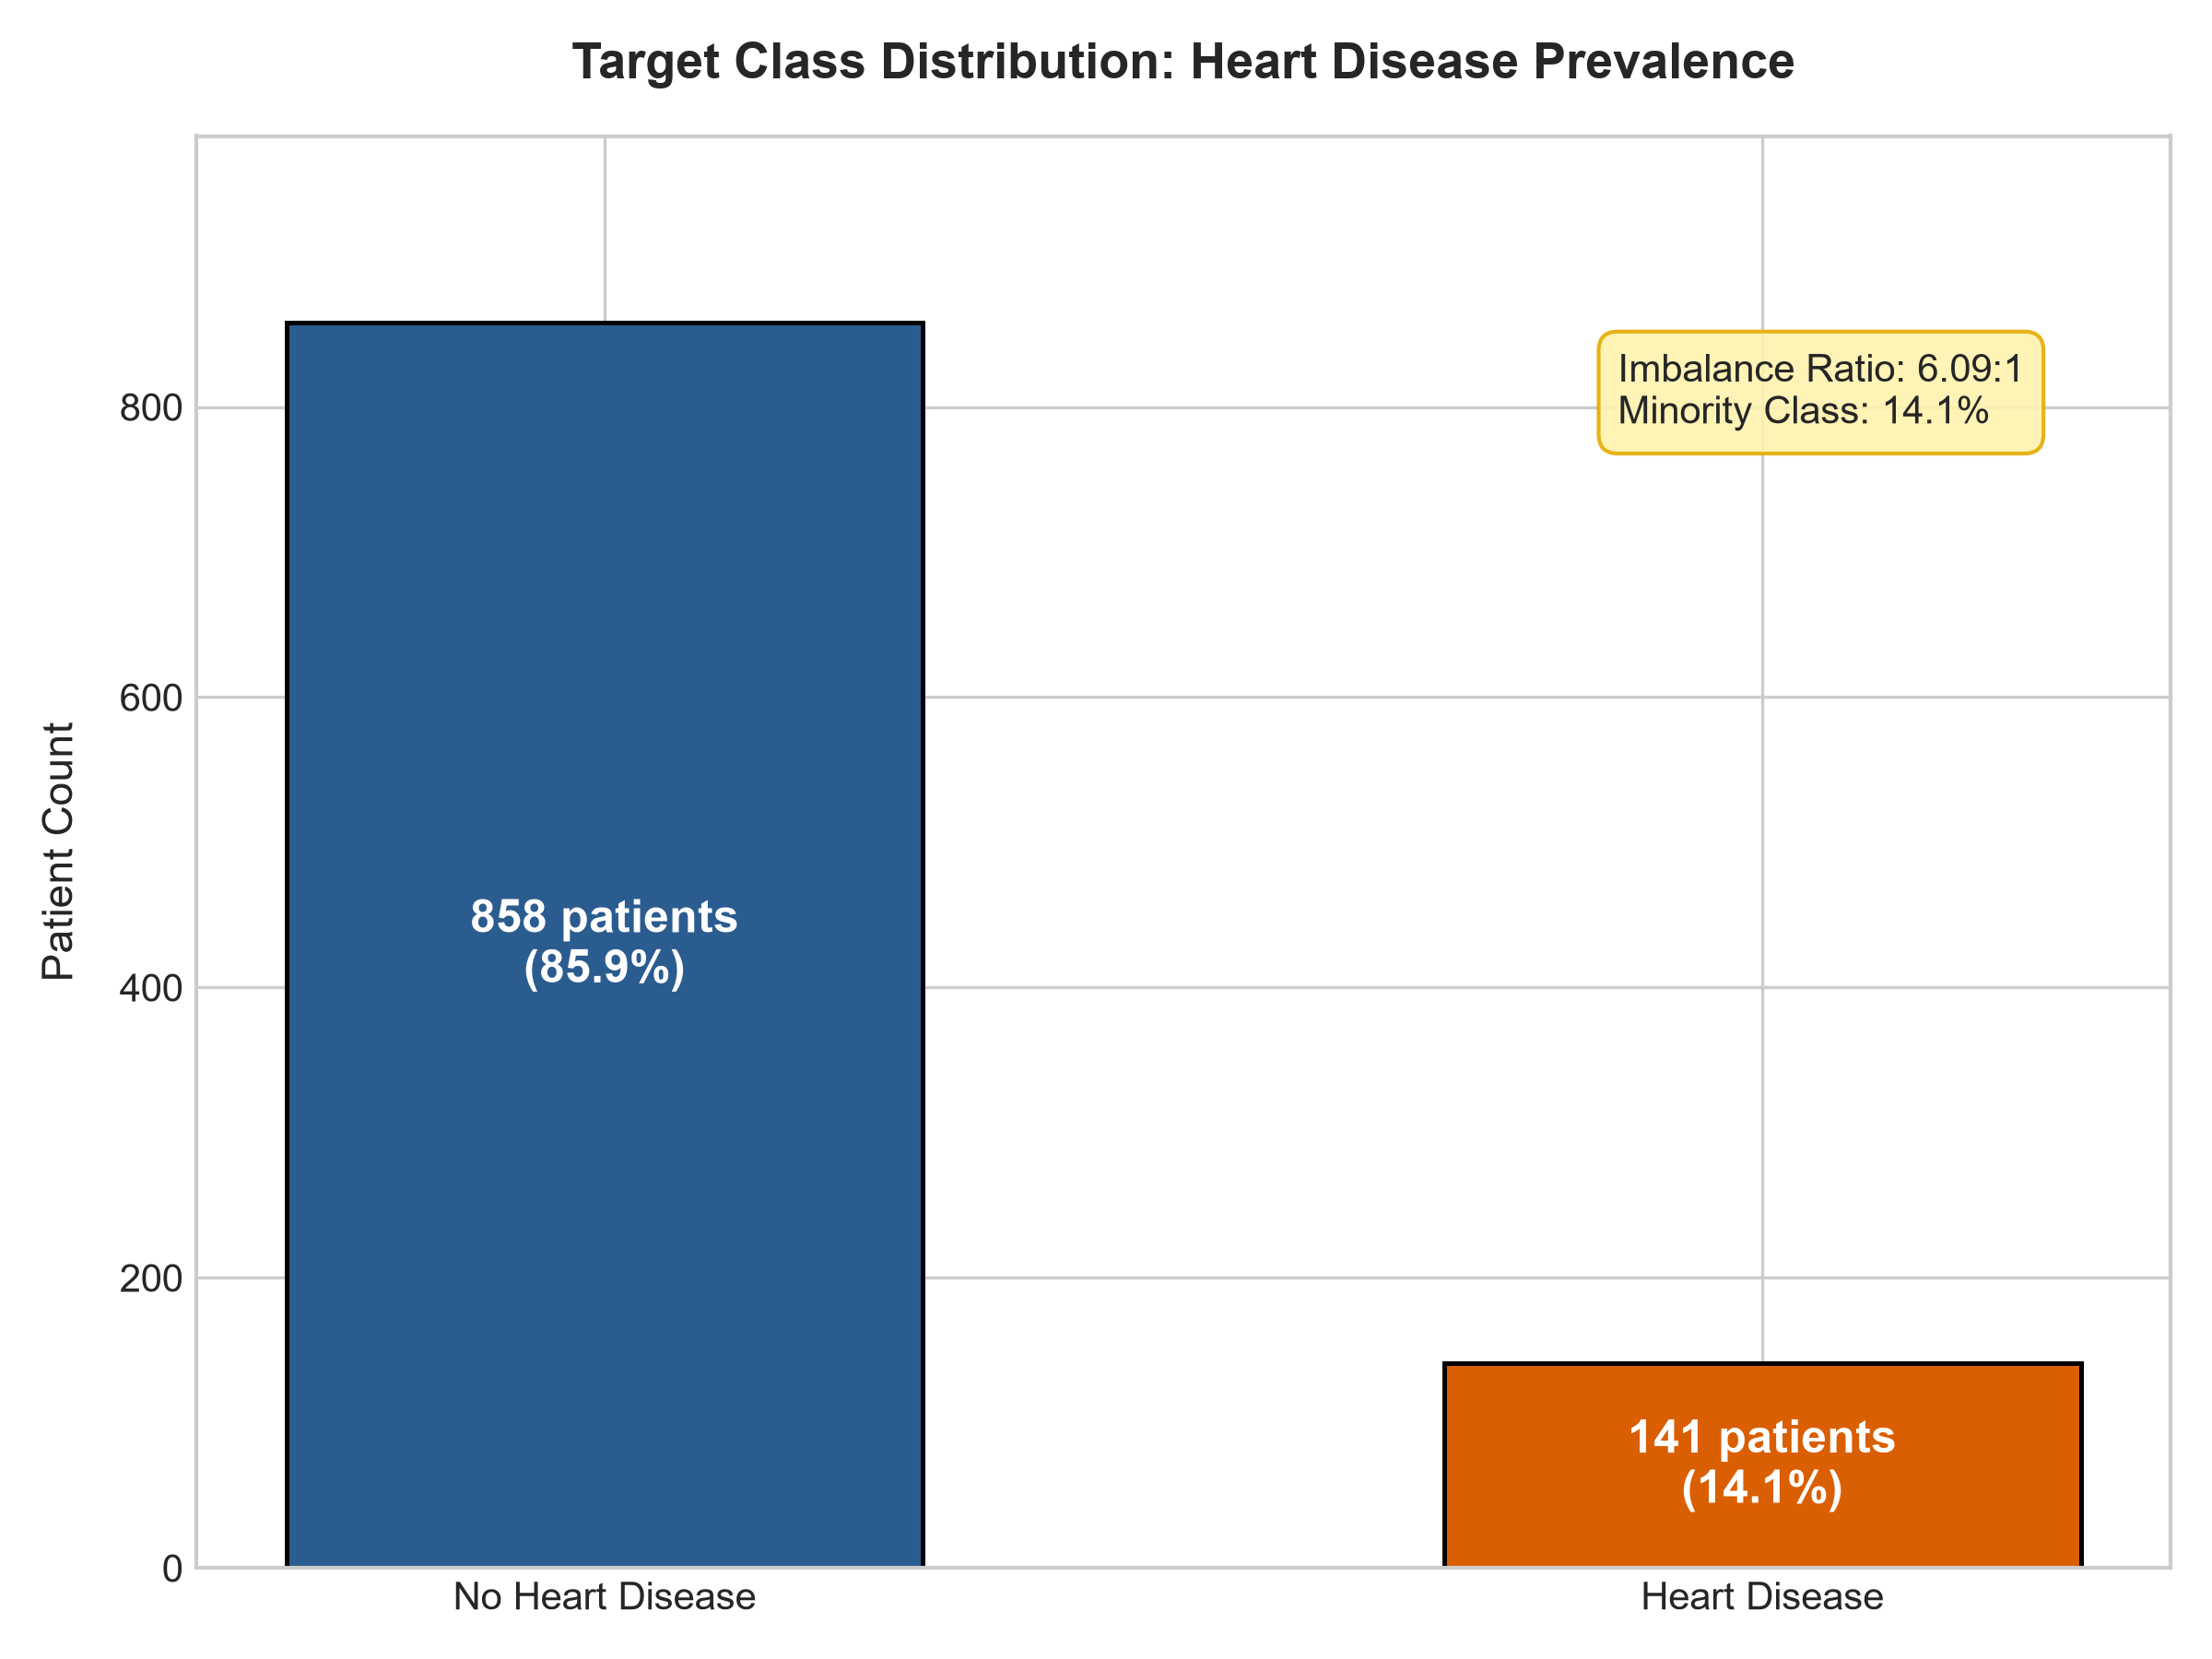


--- Figure 4: Correlation Heatmap ---


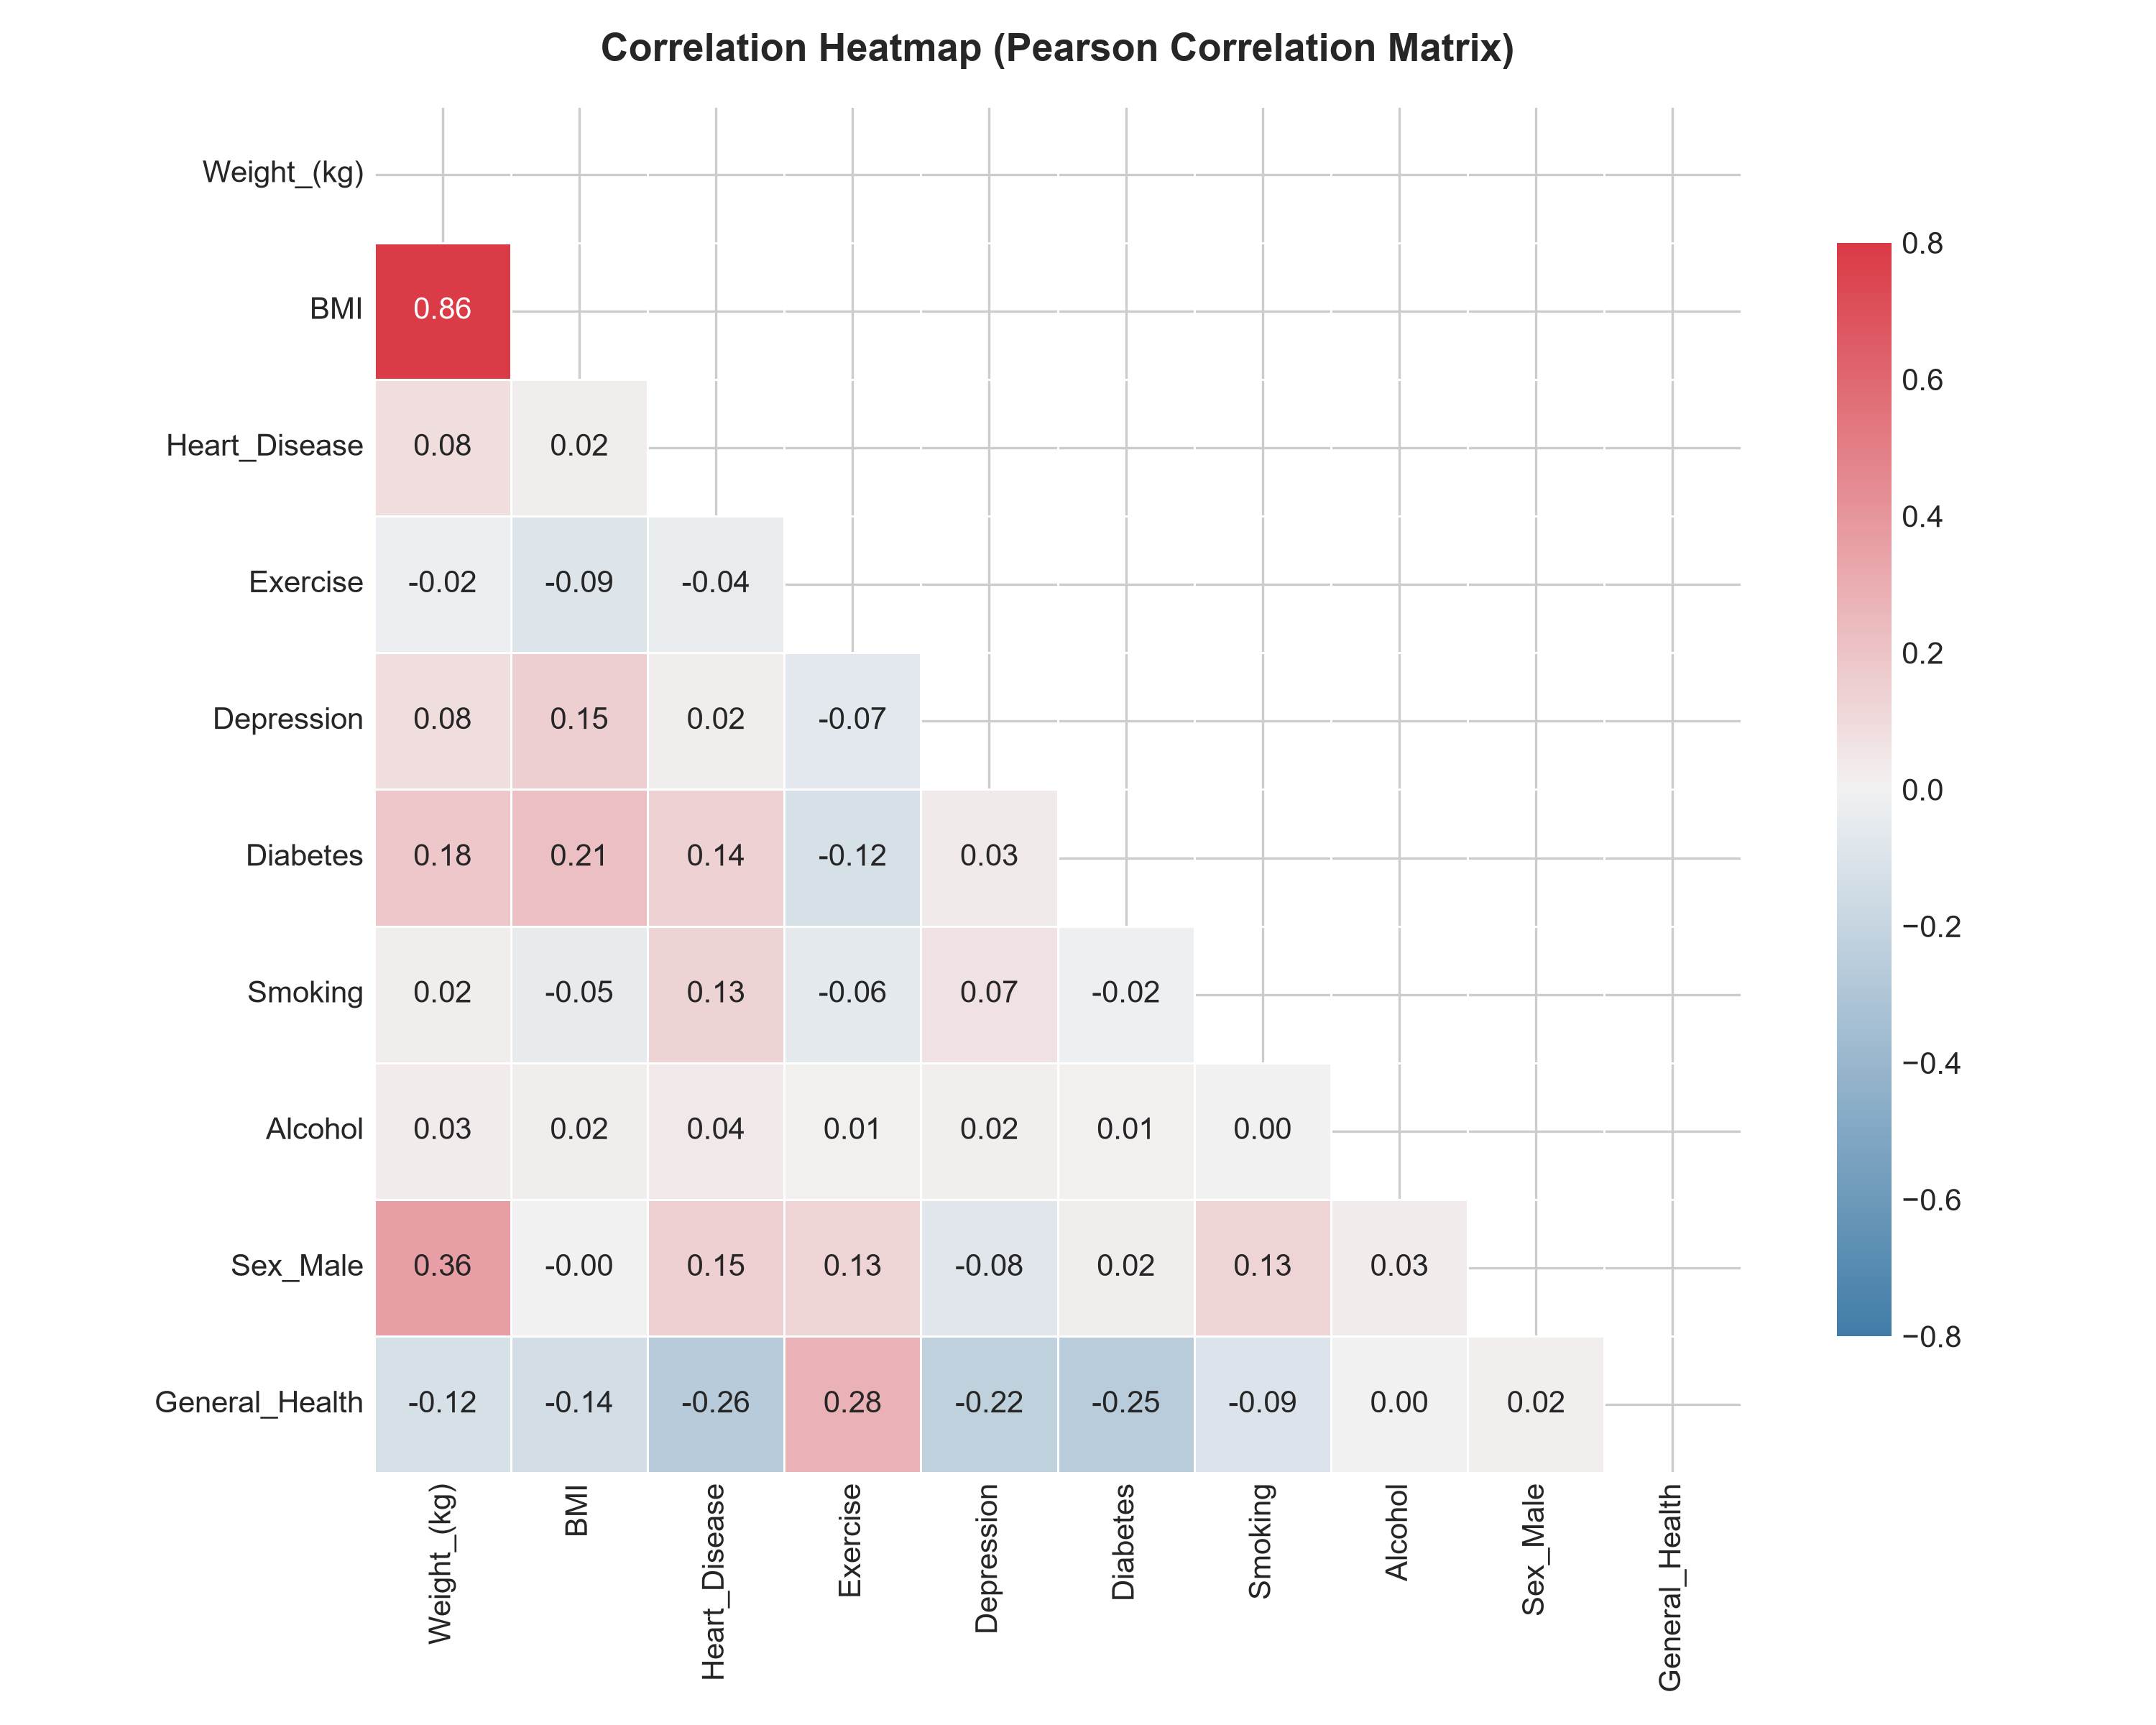


--- Figure 6: Categorical Risk Factors ---


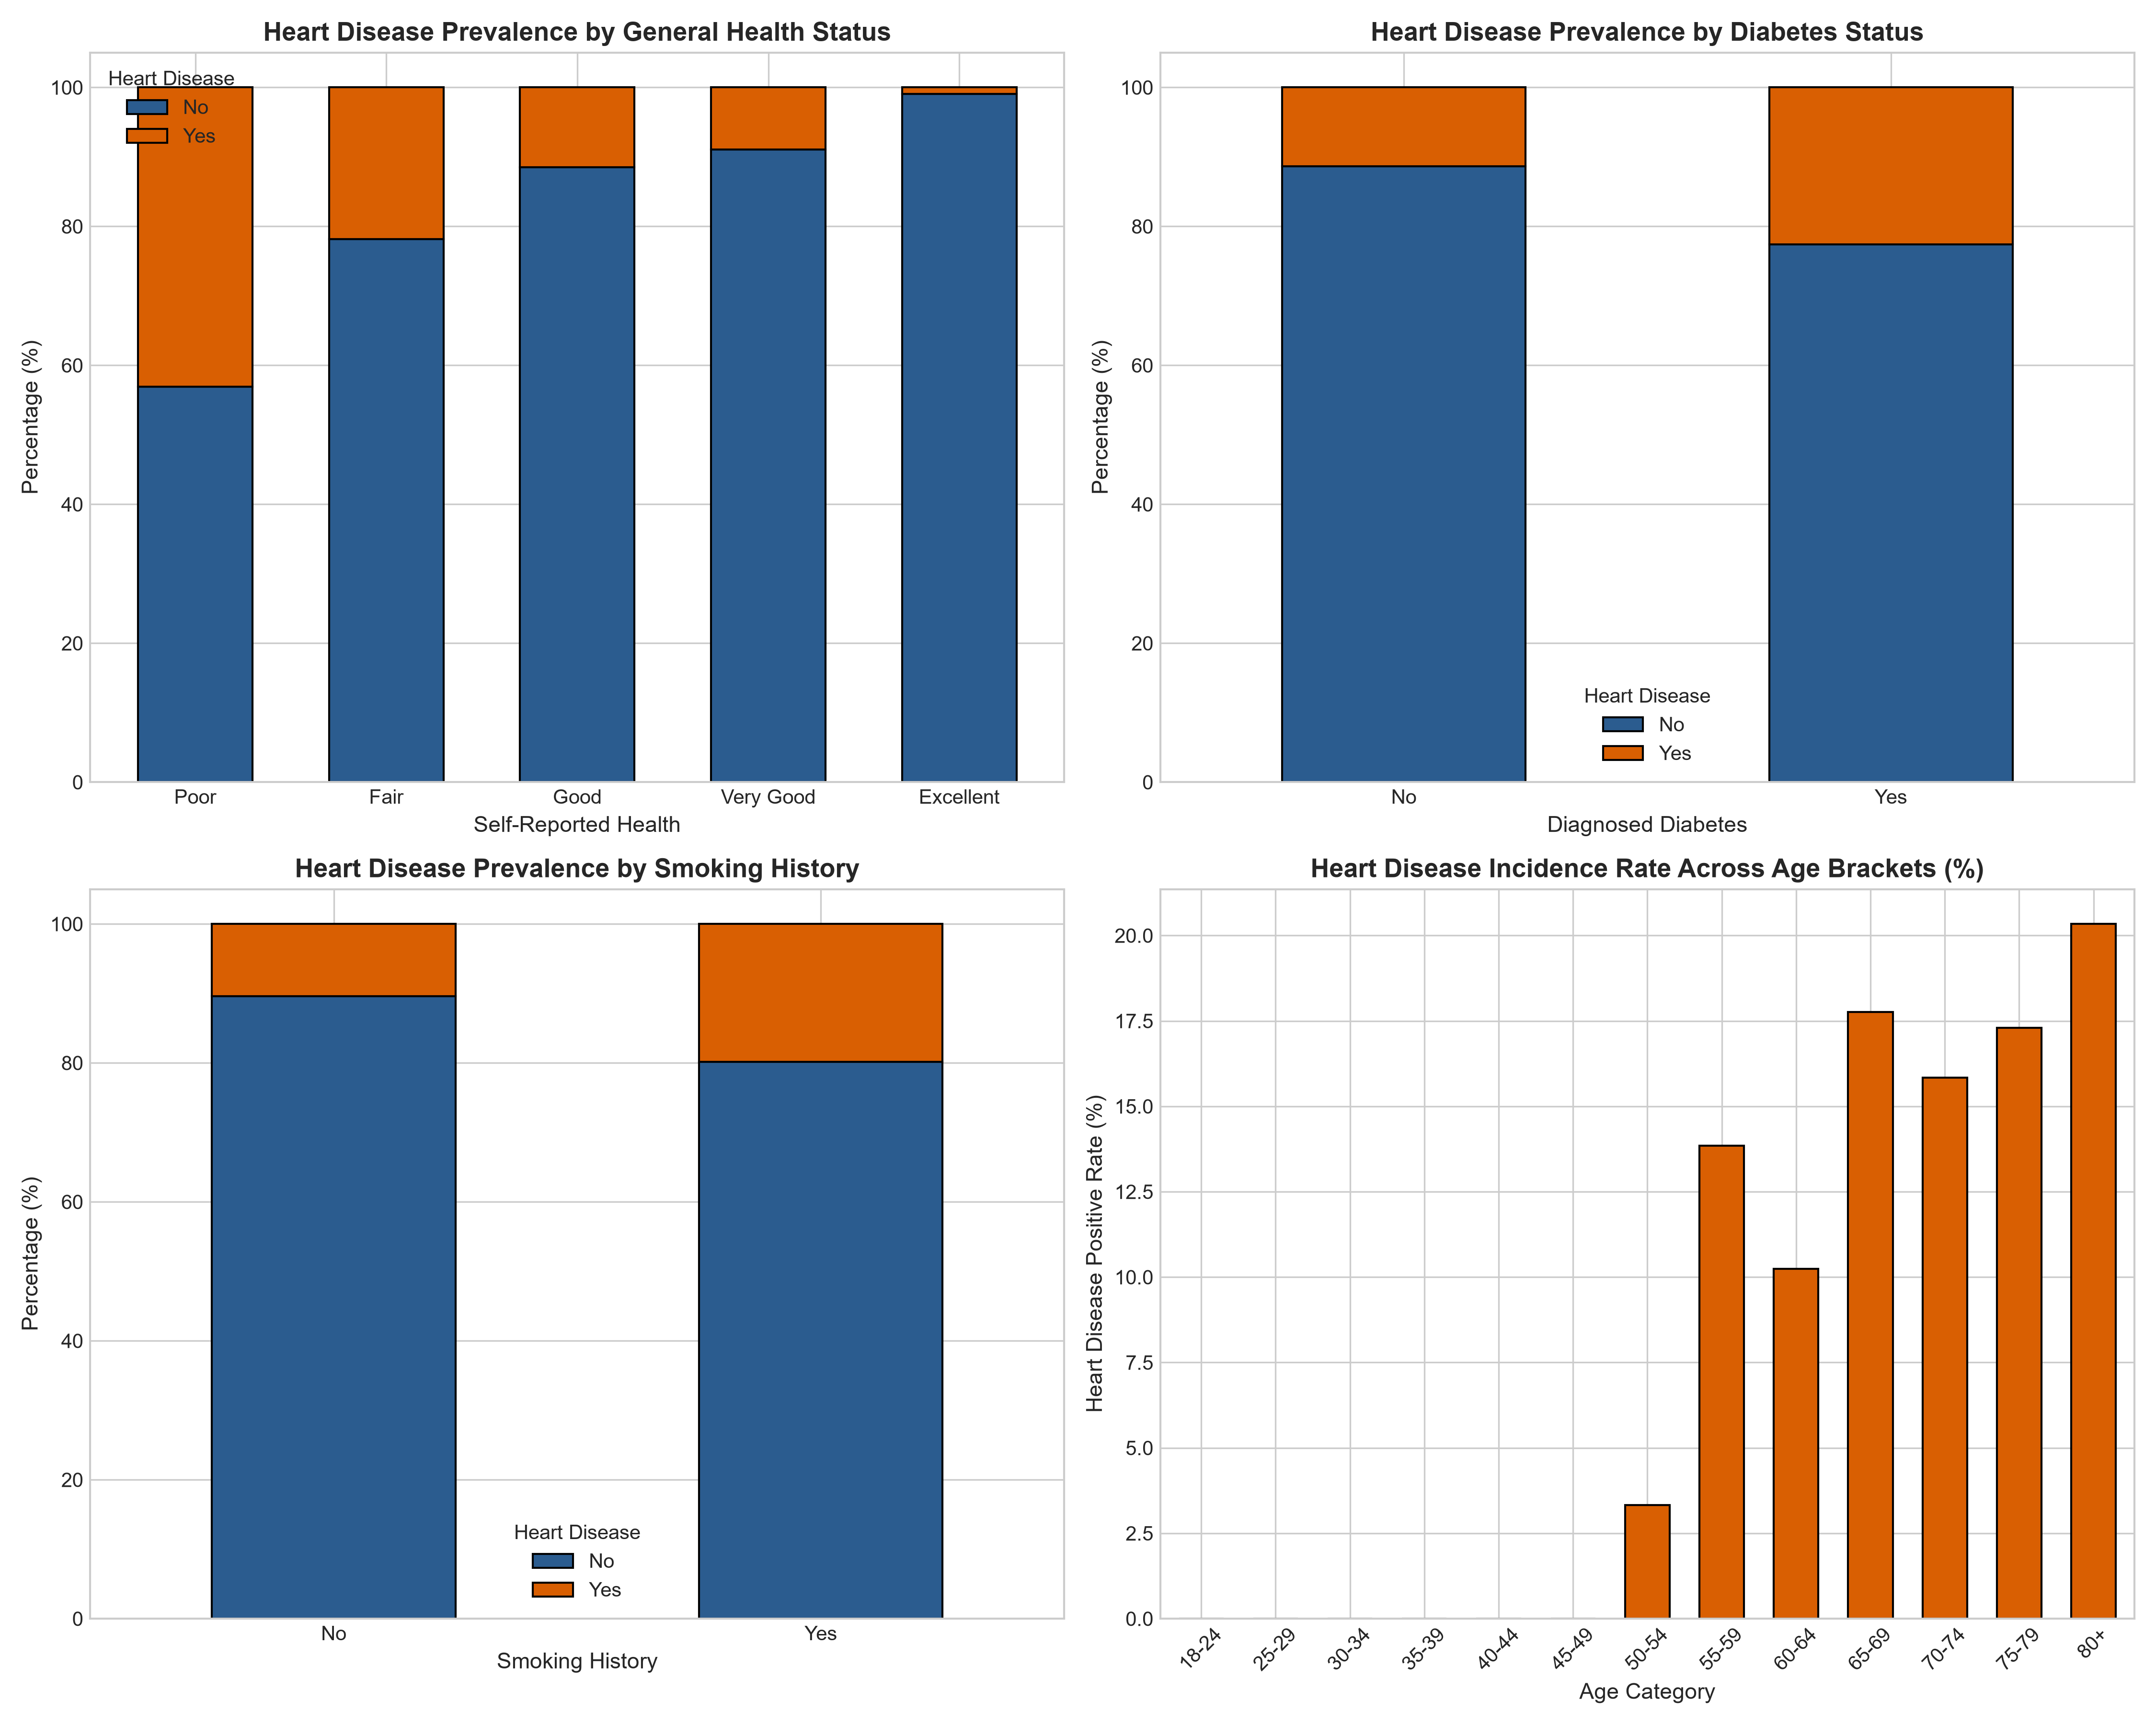

In [5]:
from src.visualizations import run_all_visualizations
from IPython.display import Image, display

plots = run_all_visualizations(
    data_path=data_path,
    output_dir=os.path.join(PROJECT_ROOT, 'outputs', 'figures')
)
print("All figures generated successfully. Displaying selected key figures:")

# Figure 1: Target Distribution
print("\n--- Figure 1: Target Class Distribution ---")
display(Image(filename=os.path.join(PROJECT_ROOT, 'outputs', 'figures', '01_target_distribution.png'), width=600))

# Figure 4: Correlation Heatmap
print("\n--- Figure 4: Correlation Heatmap ---")
display(Image(filename=os.path.join(PROJECT_ROOT, 'outputs', 'figures', '04_correlation_heatmap.png'), width=650))

# Figure 6: Categorical Risk Factors
print("\n--- Figure 6: Categorical Risk Factors ---")
display(Image(filename=os.path.join(PROJECT_ROOT, 'outputs', 'figures', '06_categorical_risk_factors.png'), width=750))


## 6. Feature Importance & Non-Linear Dependency Analysis
Multi-Layer Perceptrons route features through dense layers with non-linear activations and alternating positive/negative weights, meaning they do not possess intrinsic directional coefficients.
To achieve rigorous interpretability, we compute:
1. **Mutual Information (MI):** Quantifies non-parametric shared entropy with the target.
2. **Permutation Importance:** Measures the empirical drop in validation ROC-AUC when a feature is randomly shuffled.


2026-10-14 14:55:37,414 - INFO - Computing Mutual Information scores...
2026-10-14 14:55:37,516 - INFO - Computing Permutation Feature Importance...
2026-10-14 14:55:45,715 - INFO - Feature analysis report saved to: outputs/reports/feature_analysis_report.md
2026-10-14 14:55:45,716 - INFO - Feature analysis finished successfully.


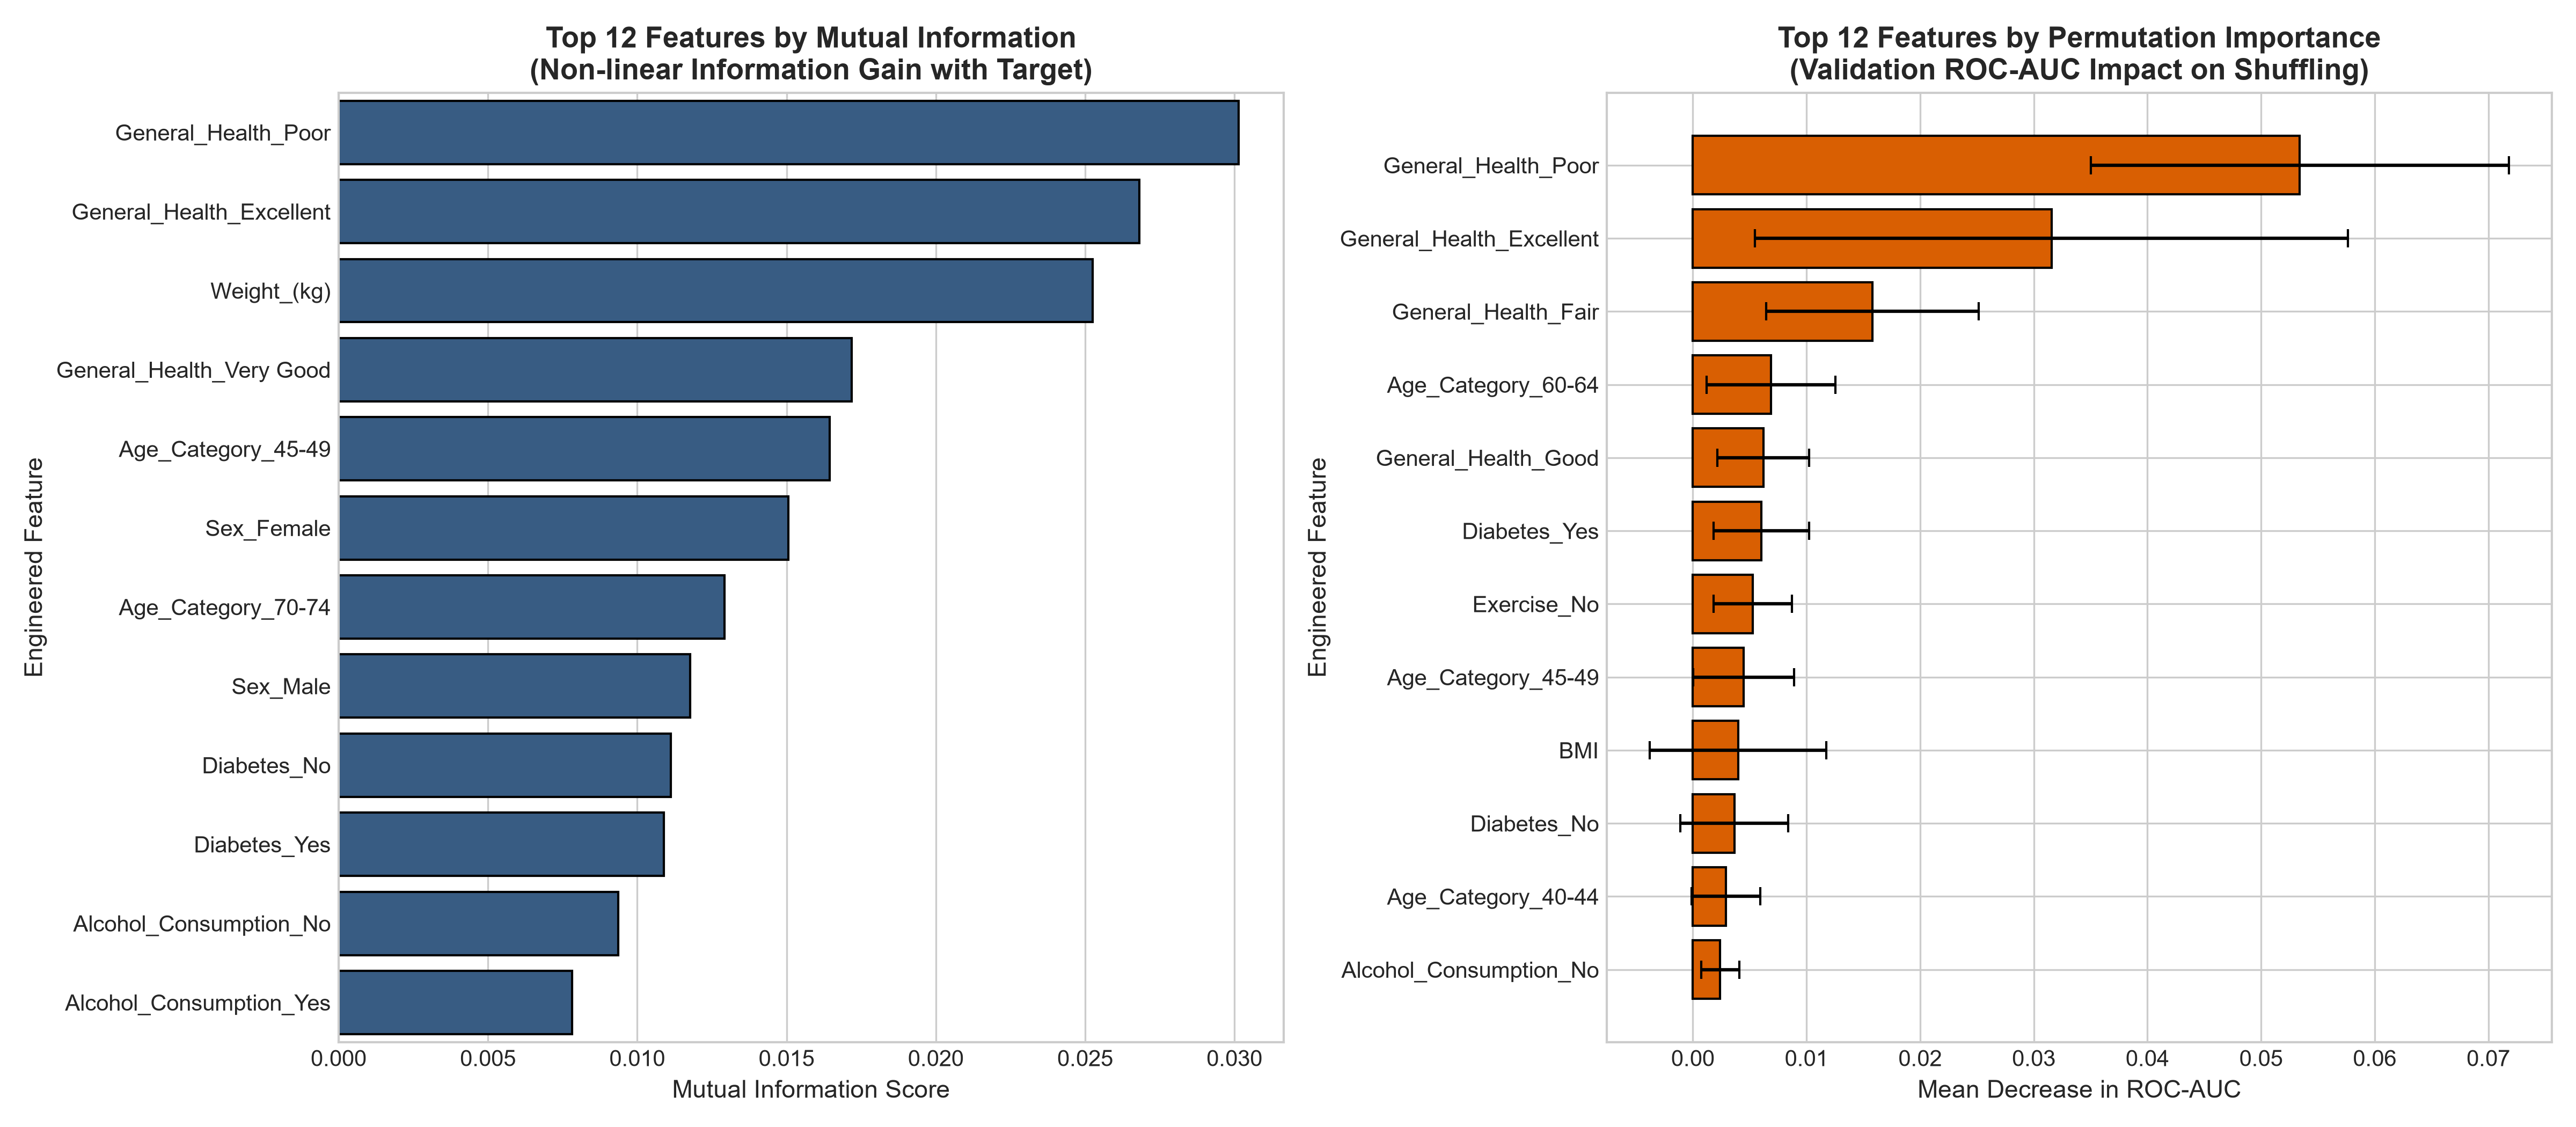

Top 10 Most Predictive Features:


,Feature,Mutual_Information,Permutation_Importance_Mean,Permutation_Importance_Std
0,Age_Category_18-24,0.000000,-0.000148,0.000760
1,Age_Category_25-29,0.000000,-0.000037,0.000747
2,Age_Category_30-34,0.003166,0.000997,0.000991
3,Age_Category_35-39,0.000000,0.000221,0.000937
4,Age_Category_40-44,0.005403,0.002916,0.003015
5,Age_Category_45-49,0.016440,0.004467,0.004434
6,Age_Category_50-54,0.005075,0.001403,0.002201
7,Age_Category_55-59,0.000000,-0.000628,0.000935
8,Age_Category_60-64,0.000000,0.006866,0.005662
9,Age_Category_65-69,0.000000,-0.001920,0.002164


In [6]:
from src.feature_analysis import run_feature_analysis

res_fa = run_feature_analysis(
    train_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'train.csv'),
    val_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'val.csv'),
    output_dir=os.path.join(PROJECT_ROOT, 'outputs', 'figures'),
    metrics_dir=os.path.join(PROJECT_ROOT, 'outputs', 'metrics')
)

display(Image(filename=res_fa['chart_path'], width=800))
feat_df = pd.read_csv(res_fa['metrics_csv'])
print("Top 10 Most Predictive Features:")
display(feat_df.head(10))


## 7. Deep Learning Hyperparameter Tuning
We perform a systematic grid search across 10 distinct neural network configurations.
All architectures are trained on the training split and evaluated strictly on the **15% validation split**, ensuring that the test set remains untouched.


2026-10-14 14:53:18,134 - INFO - Computed Class Weights: {0: 0.5825, 1: 3.5303030303030303}


2026-10-14 14:53:18,134 - INFO - Initiating tuning search across 10 configurations...


2026-10-14 14:53:18,134 - INFO - Evaluating Config_1_Baseline: units=[64, 32], dropout=0.2, lr=0.001, batch=32


2026-10-14 14:53:18,335 - WARNING - TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.


2026-10-14 14:53:25,959 - INFO - Evaluating Config_2_Wider: units=[128, 64], dropout=0.3, lr=0.001, batch=32


...

2026-10-14 14:54:31,202 - INFO - Tuning results written to: D:\heart-disease-risk-prediction\outputs\metrics\hyperparameter_tuning_results.csv


2026-10-14 14:54:31,827 - INFO - Tuning comparison plot saved to: D:\heart-disease-risk-prediction\outputs\figures\10_hyperparameter_tuning_comparison.png


2026-10-14 14:54:31,834 - INFO - Optimal configuration selected: Config_7_HighDropout (val_auc=0.7896)


Optimal Configuration Selected: Config_7_HighDropout
Validation ROC-AUC: 0.7896
Validation Recall: 0.2381


,config_id,hidden_units,dropout_rate,learning_rate,batch_size,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_f1,epochs_trained
6,Config_7_HighDropout,"[128, 64]",0.4,0.0010,32,0.4390,0.8267,0.3333,0.2381,0.7896,0.2778,23
2,Config_3_Deeper,"[64, 32, 16]",0.2,0.0010,32,0.5083,0.7933,0.3611,0.6190,0.7604,0.4561,36
7,Config_8_SmallBatch,"[64, 32]",0.2,0.0010,16,0.4569,0.8400,0.4444,0.5714,0.7575,0.5000,24
8,Config_9_LargeBatch,"[64, 32]",0.2,0.0010,64,0.4910,0.7933,0.2917,0.3333,0.7442,0.3111,32
4,Config_5_LowLR,"[64, 32]",0.2,0.0005,32,0.5138,0.7667,0.3158,0.5714,0.7420,0.4068,29
9,Config_10_Regularized,"[64, 32, 16]",0.3,0.0005,32,0.5210,0.7800,0.3000,0.4286,0.7364,0.3529,50
1,Config_2_Wider,"[128, 64]",0.3,0.0010,32,0.4584,0.8467,0.4500,0.4286,0.7350,0.4390,38
0,Config_1_Baseline,"[64, 32]",0.2,0.0010,32,0.4299,0.8133,0.3158,0.2857,0.7331,0.3000,34
5,Config_6_HighLR,"[64, 32]",0.2,0.0020,32,0.4318,0.8400,0.3636,0.1905,0.7172,0.2500,23
3,Config_4_Compact,"[32, 16]",0.1,0.0010,32,0.5273,0.8000,0.3448,0.4762,0.6681,0.4000,30


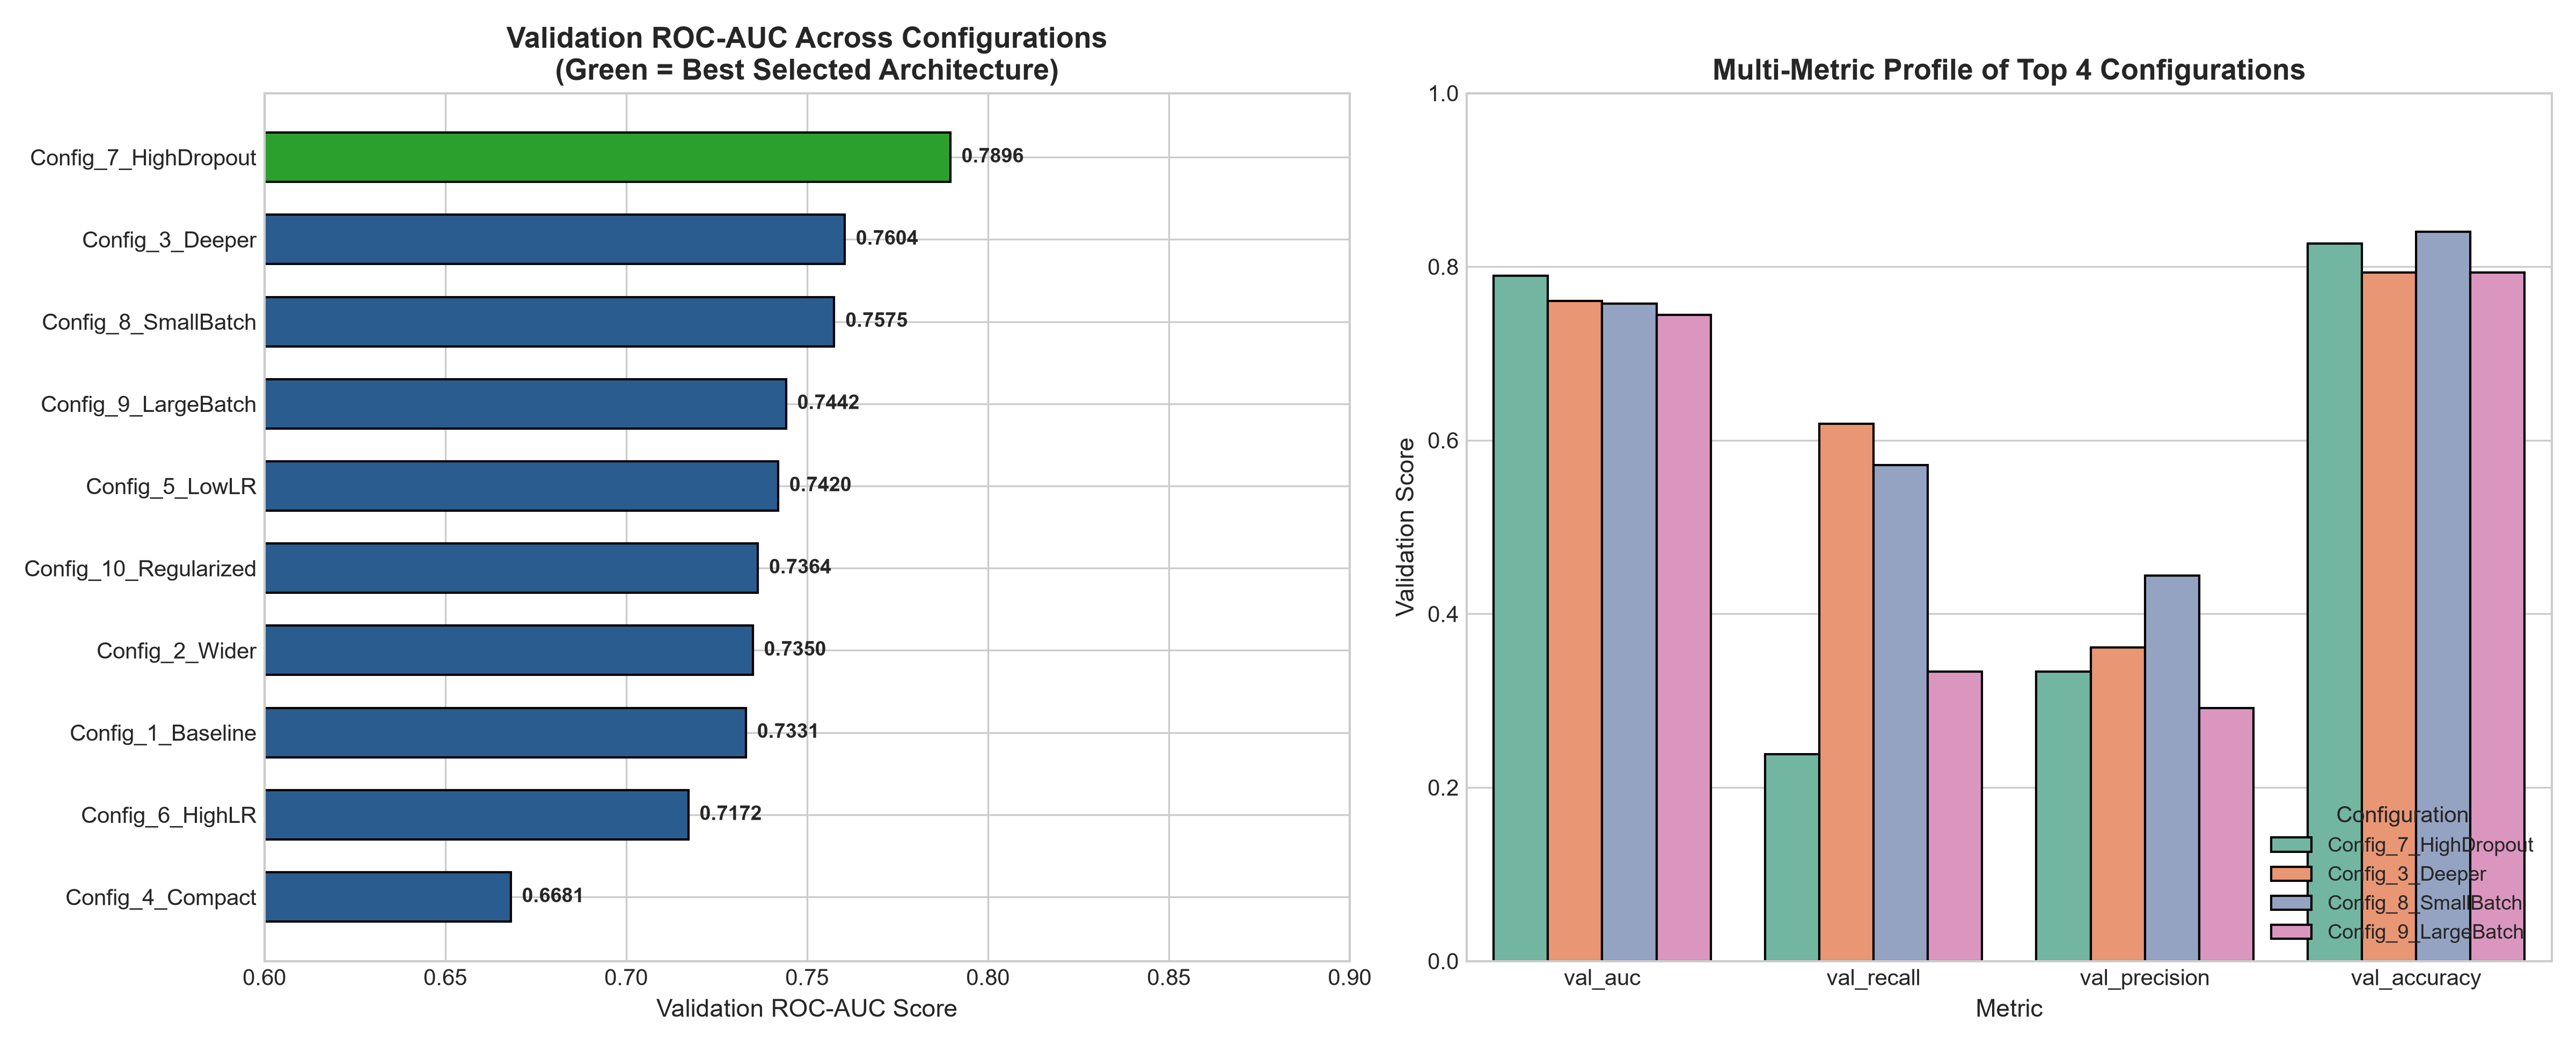

In [7]:
from src.hyperparameter_tuning import run_hyperparameter_tuning

best_meta = run_hyperparameter_tuning(
    train_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'train.csv'),
    val_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'val.csv'),
    output_metrics_dir=os.path.join(PROJECT_ROOT, 'outputs', 'metrics'),
    output_figures_dir=os.path.join(PROJECT_ROOT, 'outputs', 'figures'),
    models_dir=os.path.join(PROJECT_ROOT, 'models')
)

print(f"Optimal Configuration Selected: {best_meta['best_config_id']}")
print(f"Validation ROC-AUC: {best_meta['validation_performance']['val_auc']:.4f}")
print(f"Validation Recall: {best_meta['validation_performance']['val_recall']:.4f}")

tuning_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'outputs', 'metrics', 'hyperparameter_tuning_results.csv'))
display(tuning_df.sort_values(by='val_auc', ascending=False))
display(Image(filename=os.path.join(PROJECT_ROOT, 'outputs', 'figures', '10_hyperparameter_tuning_comparison.png'), width=800))


## 8. Final Model Benchmark on Untouched Test Set
We train the final Multi-Layer Perceptron using the optimal hyperparameter configuration, calibrate the decision threshold on validation data ($	heta = 0.480$), and benchmark against the **150 untouched test samples**.


In [8]:
from src.model_evaluation import run_model_evaluation

eval_res = run_model_evaluation(
    train_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'train.csv'),
    val_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'val.csv'),
    test_path=os.path.join(PROJECT_ROOT, 'data', 'processed', 'test.csv'),
    best_params_path=os.path.join(PROJECT_ROOT, 'models', 'best_hyperparameters.json'),
    model_save_path=os.path.join(PROJECT_ROOT, 'models', 'final_model.keras'),
    figures_dir=os.path.join(PROJECT_ROOT, 'outputs', 'figures'),
    metrics_dir=os.path.join(PROJECT_ROOT, 'outputs', 'metrics')
)

print("\n--- Final Test Set Benchmark Results (Untouched Holdout) ---")
for k, v in eval_res['metrics_at_optimal_threshold'].items():
    print(f"  {k:20s}: {v}")


2026-10-14 14:54:31,873 - INFO - Training final MLP with selected parameters: {'config_id': 'Config_7_HighDropout', 'hidden_units': [128, 64], 'dropout_rate': 0.4, 'learning_rate': 0.001, 'batch_size': 32}


2026-10-14 14:54:31,942 - INFO - Computed Class Weights: {0: 0.5825, 1: 3.5303030303030303}


Epoch 1/100



 1/22 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.5000 - auc: 0.4943 - loss: 0.8305 - precision: 0.0667 - recall: 0.3333


Epoch 1: val_auc improved from None to 0.54171, saving model to D:\heart-disease-risk-prediction\models\final_model.keras


...

2026-10-14 14:54:38,068 - INFO - Evaluating final model on untouched test set...


2026-10-14 14:54:38,176 - INFO - Test metrics saved to: D:\heart-disease-risk-prediction\outputs\metrics\test_metrics.json


2026-10-14 14:54:39,661 - INFO - Model metadata saved to D:\heart-disease-risk-prediction\models\model_metadata.json


2026-10-14 14:54:39,662 - INFO - Evaluation pipeline finished successfully.



--- Final Test Set Benchmark Results (Untouched Holdout) ---
  accuracy            : 0.76
  precision           : 0.2727
  recall_sensitivity  : 0.4286
  specificity         : 0.814
  f1_score            : 0.3333
  roc_auc             : 0.6929
  true_negatives      : 105
  false_positives     : 24
  false_negatives     : 12
  true_positives      : 9


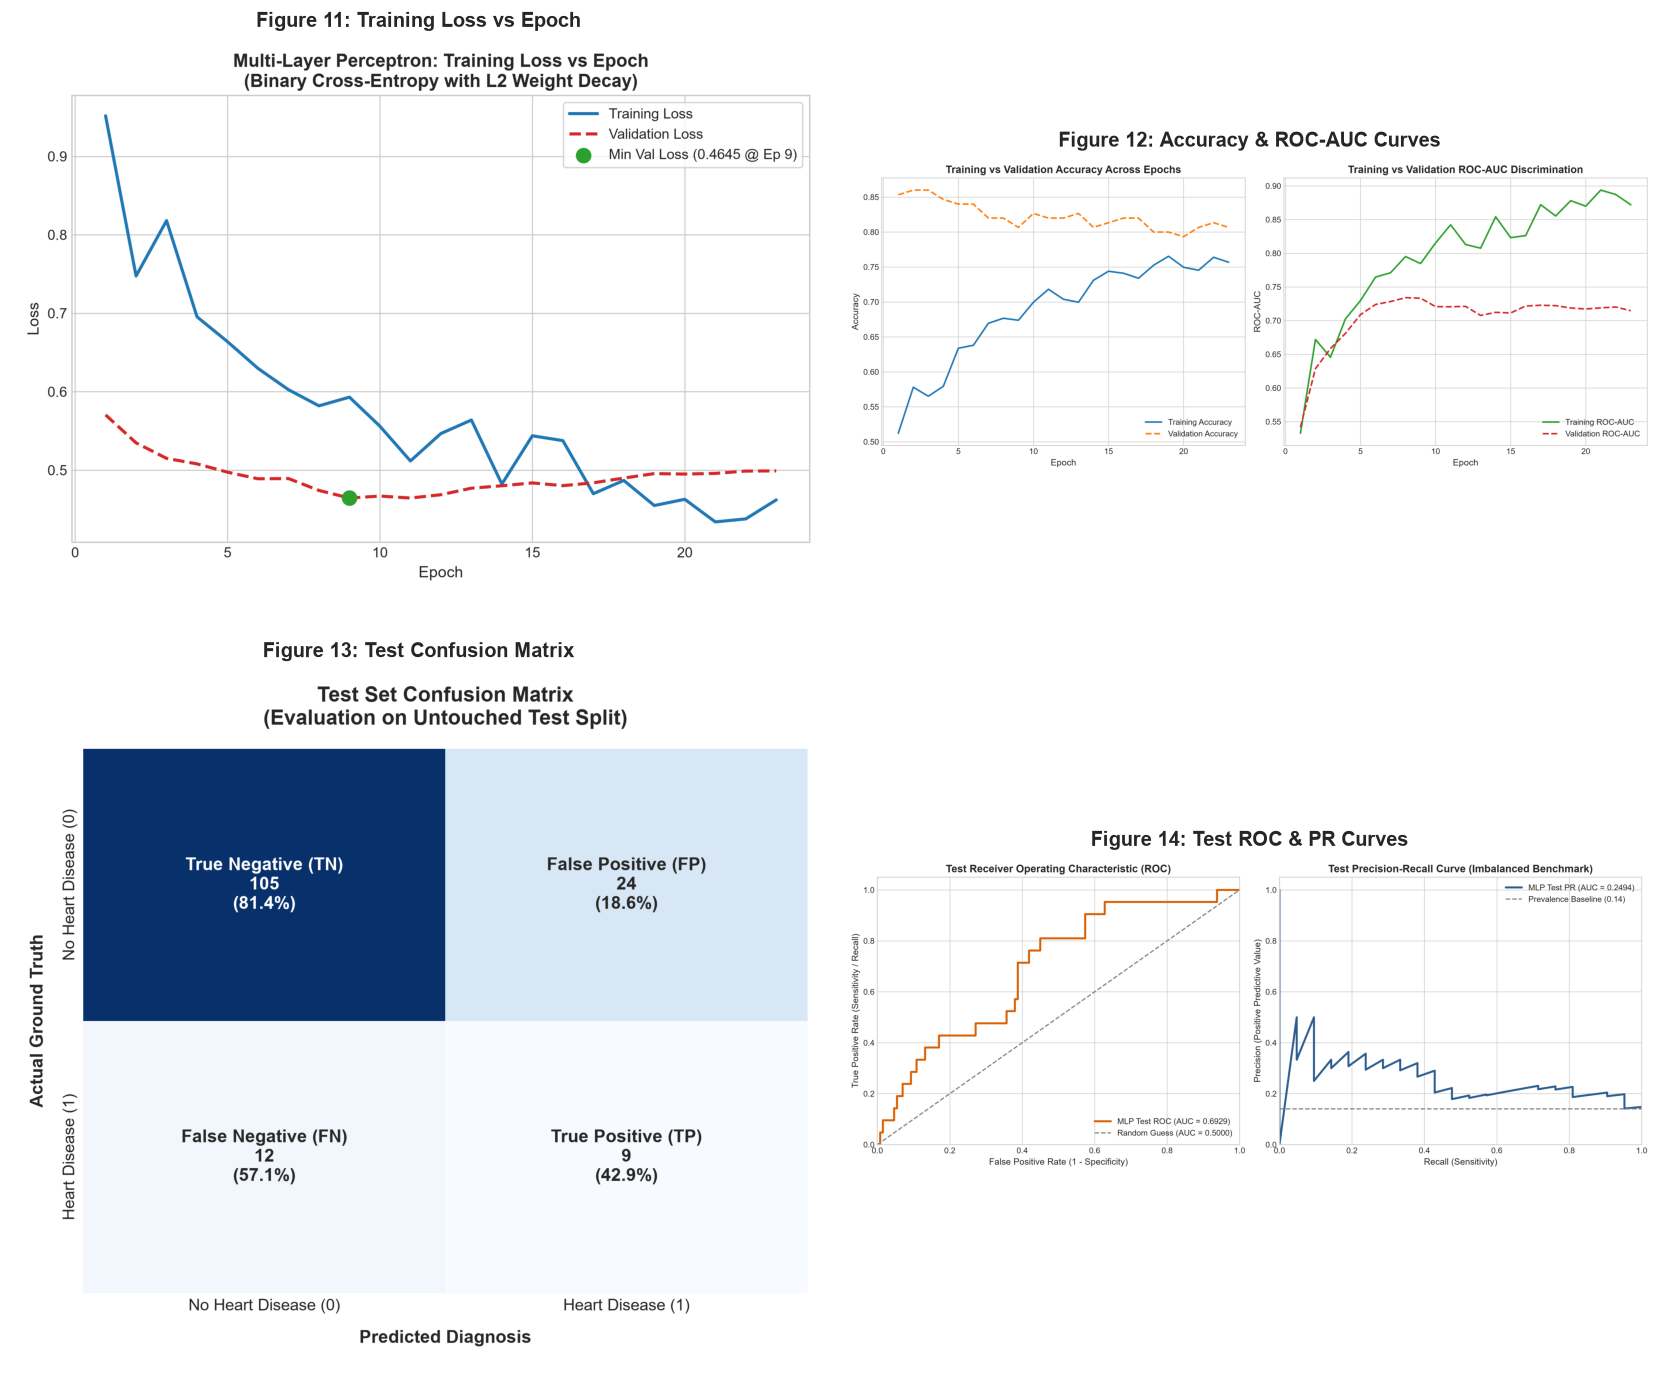

In [7]:
# Display 4 Evaluation Diagnostic Plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(plt.imread(os.path.join(PROJECT_ROOT, 'outputs', 'figures', '11_training_loss_curves.png')))
axes[0, 0].axis('off')
axes[0, 0].set_title('Figure 11: Training Loss vs Epoch', fontsize=12, fontweight='bold')

axes[0, 1].imshow(plt.imread(os.path.join(PROJECT_ROOT, 'outputs', 'figures', '12_training_accuracy_curves.png')))
axes[0, 1].axis('off')
axes[0, 1].set_title('Figure 12: Accuracy & ROC-AUC Curves', fontsize=12, fontweight='bold')

axes[1, 0].imshow(plt.imread(os.path.join(PROJECT_ROOT, 'outputs', 'figures', '13_confusion_matrix.png')))
axes[1, 0].axis('off')
axes[1, 0].set_title('Figure 13: Test Confusion Matrix', fontsize=12, fontweight='bold')

axes[1, 1].imshow(plt.imread(os.path.join(PROJECT_ROOT, 'outputs', 'figures', '14_roc_curve.png')))
axes[1, 1].axis('off')
axes[1, 1].set_title('Figure 14: Test ROC & PR Curves', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 9. Model Inference & Clinical Risk Prediction
We test the production prediction pipeline on hypothetical patient profiles to demonstrate real-time risk scoring and risk indicator extraction.


In [8]:
from src.predict import predict_heart_disease

sample_patient_low = {
    'General_Health': 'Excellent',
    'Exercise': 'Yes',
    'Depression': 'No',
    'Diabetes': 'No',
    'Sex': 'Female',
    'Age_Category': '30-34',
    'Weight_(kg)': 60.0,
    'BMI': 22.0,
    'Smoking_History': 'No',
    'Alcohol_Consumption': 'No'
}

sample_patient_high = {
    'General_Health': 'Poor',
    'Exercise': 'No',
    'Depression': 'Yes',
    'Diabetes': 'Yes',
    'Sex': 'Male',
    'Age_Category': '75-79',
    'Weight_(kg)': 102.0,
    'BMI': 35.5,
    'Smoking_History': 'Yes',
    'Alcohol_Consumption': 'No'
}

print("=== Case 1: Young Healthy Female Subject ===")
pred_low = predict_heart_disease(sample_patient_low)
print(f"Prediction: {pred_low['prediction_label']}")
print(f"Model Probability: {pred_low['model_probability_percentage']}%")
print(f"Risk Tier: {pred_low['risk_tier']}")
print(f"Guidance: {pred_low['clinical_recommendation']}")

print("\n=== Case 2: Elderly Male Subject with Comorbidities ===")
pred_high = predict_heart_disease(sample_patient_high)
print(f"Prediction: {pred_high['prediction_label']}")
print(f"Model Probability: {pred_high['model_probability_percentage']}%")
print(f"Risk Tier: {pred_high['risk_tier']}")
print(f"Guidance: {pred_high['clinical_recommendation']}")
print("Contributing Indicators:", pred_high['notable_contributing_factors'])


2026-10-14 14:56:26,921 - INFO - Preprocessor loaded successfully from D:\heart-disease-risk-prediction\models\preprocessor.joblib


=== Case 1: Young Healthy Female Subject ===


2026-10-14 14:56:27,130 - WARNING - TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.
2026-10-14 14:56:27,216 - INFO - Predictor artifacts loaded successfully.
2026-10-14 14:56:27,494 - INFO - Preprocessor loaded successfully from D:\heart-disease-risk-prediction\models\preprocessor.joblib
2026-10-14 14:56:27,565 - INFO - Predictor artifacts loaded successfully.


Prediction: No Heart Disease Detected
Model Probability: 14.55%
Risk Tier: Low Relative Risk
Guidance: Maintain routine preventative healthy lifestyle habits.

=== Case 2: Elderly Male Subject with Comorbidities ===
Prediction: Heart Disease Risk Detected
Model Probability: 61.11%
Risk Tier: High Relative Risk
Guidance: Advise comprehensive medical screening and consultation with a healthcare professional.
Contributing Indicators: ['Self-reported health is Poor', 'Diagnosed with diabetes', 'Positive smoking history', 'Age category (75-79) carries elevated baseline demographic incidence', 'BMI (35.5) is in the obese range (>= 30)', 'Absence of regular physical exercise']
